<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Entity Resolution](https://github.com/Query-farm/vgi-match)

Find duplicate records and link the same real-world entity across tables with probabilistic matching.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-match/blob/main/notebooks/01_audit_duplicate_groups.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-match/blob/main/notebooks/README.md)


## 01 · Audit duplicate groups before trusting a score

**Does a higher matching threshold improve our duplicate groups?** We will send seven
worker-supplied synthetic customer rows to the real Splink-backed VGI worker, compare its clusters
with the sample's authored labels, and measure which record pairs are recovered or
missed. The experiment raises the threshold while keeping all input rows fixed.

These are invented records with reserved example-domain email addresses. The labels
are a teaching fixture, not validated identities. Agreement on this tiny example is
not a benchmark or evidence that the model's probabilities are calibrated for real customers.

### Choose the pair-link threshold

Start with `THRESHOLD=0.5`; later try `0.9999`. Restart the kernel and run all cells
after changing it. This notebook accepts `0 < THRESHOLD < 1`: the tested Splink 5.0.0
runtime fails at the exact endpoint `1.0` when it generates an infinite SQL cutoff.

Training stays explicitly disabled. Seven authored rows are too small to estimate a
useful model. The worker uses its default comparisons and prior; changing a threshold
changes which pair links are retained, not the evidence in the input.

In [1]:
THRESHOLD = 0.5

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.9":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.9"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402 — import follows bootstrap install

check_runtime()

In [3]:
from vgi_notebooks import connect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from IPython.display import display
from vgi_notebooks.presentation import finish, prose, theme

if isinstance(THRESHOLD, bool) or not isinstance(THRESHOLD, (int, float)) or not 0 < THRESHOLD < 1:
    raise ValueError(
        "THRESHOLD must be a finite number strictly between 0 and 1; try 0.5 or 0.9999."
    )
theme()
SOURCE = "Source: worker-supplied synthetic customer sample · VGI Match v0.4.0 · Splink 5.0.0"
session = connect(globals())

### Attach the published worker release

The short `uvx` command installs public **v0.4.0** in a separate worker environment. It needs `uv`, Git and network access on first use; `uv` can provision Python 3.14. The tested resolver supplies Splink 5.0.0 and the worker's declared dependencies, without installing them in the notebook kernel or adding hidden overrides. No local worker checkout is needed.

The shared notebook bootstrap installs only base dependencies in Colab; local publication adds `[runner]`. The SQL connection starts with an empty temporary secret directory and persistent secrets disabled. There are no credentials, external customer records or account writes.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'match' (TYPE vgi,
 LOCATION 'uvx --python 3.14 --from git+https://github.com/Query-farm/vgi-match@v0.4.0 vgi-match');

,Success


### Inspect the shipped sample and its planted groups

The public `sample_customers` relation supplies seven invented records and an `expected_entity` label. Materialize it once, then count the supplied groups before matching. This makes the expected duplicate structure visible instead of treating a high score as truth. The sample and labels come from the same worker project; their agreement is a teaching check, not independent validation or a performance benchmark.

In [5]:
%%sql
CREATE TABLE demo_rows AS SELECT * FROM match.main.sample_customers;
SELECT expected_entity AS authored_group,count(*) AS records,
       string_agg(first_name,', ' ORDER BY record_id) AS name_variants
FROM demo_rows GROUP BY expected_entity ORDER BY records DESC,authored_group;

,authored_group,records,name_variants
0,"Smith, John",3,"John, Jon, Johnny"
1,"Doe, Jane",2,"Jane, Janet"
2,"Jones, Alice",1,Alice
3,"Jones, Robert",1,Robert


The Smith and Doe labels intentionally group name variants; the two Jones labels remain separate despite a shared surname. Those are the pairs the later audit must recover without merging distinct labeled groups. The next projection separates comparison inputs from evaluation labels.

### Keep the evaluation labels out of the matching input

Rows R1–R3 are authored variants of one customer, R4–R5 of another, and R6 and R7
are separate customers who share a surname. `city` and `record_id` pass through the
worker but are excluded from the comparison list. We project the shipped `expected_entity` label into a separate `fixture_truth` table,
which is joined **after** matching. That label is never passed to `match_resolve`.
The display row IDs add an `R` prefix to the sample’s integer IDs.

Use a stable, unique row key. Do not use `cluster_id`, `match_probability`, or the
worker's internal `__vgi_match_uid` as input column names.

In [6]:
%%sql
CREATE TABLE customers AS
SELECT 'R'||record_id::VARCHAR AS record_id,first_name,last_name,email,city
FROM demo_rows;
CREATE TABLE fixture_truth AS
SELECT 'R'||record_id::VARCHAR AS record_id,expected_entity AS authored_customer
FROM demo_rows;
SELECT * FROM customers ORDER BY record_id;

,record_id,first_name,last_name,email,city
0,R1,John,Smith,jsmith@example.com,New York
1,R2,Jon,Smith,jsmith@example.com,New York
2,R3,Johnny,Smith,jsmith@example.com,New York
3,R4,Jane,Doe,jane.doe@example.com,Los Angeles
4,R5,Janet,Doe,jane.doe@example.com,Los Angeles
5,R6,Robert,Jones,rjones@example.com,San Francisco
6,R7,Alice,Jones,alice.j@example.com,Seattle


### Resolve once, then reuse the materialized result

The relation is the first argument to `match_resolve`; named arguments control the
comparison columns, cutoff and training. With the default settings, pairs are
candidates only when they agree exactly on at least one comparison column. Name
columns then use fuzzy name comparisons; email uses edit-distance comparisons.
Rows differing in every comparison column can be missed by this blocking rule.

Retained links form connected components. Two rows in a cluster can be connected
through a third row without their own direct link exceeding the threshold. The
worker buffers the entire input and runs its own DuckDB instance: this is not a
streaming operator. Materializing the result also avoids rerunning it for charts.

In [7]:
%%sql
CREATE TABLE resolved AS
SELECT * FROM match.main.match_resolve(
 (SELECT * FROM customers ORDER BY record_id),
 columns := 'first_name,last_name,email',
 threshold := {{ THRESHOLD }},
 train := false
);
CREATE TABLE cluster_audit AS
SELECT r.*,t.authored_customer,count(*) OVER (PARTITION BY r.cluster_id) AS cluster_size
FROM resolved r JOIN fixture_truth t USING(record_id);
SELECT record_id,first_name,cluster_id,cluster_size,match_probability,authored_customer
FROM cluster_audit ORDER BY record_id;

,record_id,first_name,cluster_id,cluster_size,match_probability,authored_customer
0,R1,John,0,3,0.999505,"Smith, John"
1,R2,Jon,0,3,0.999505,"Smith, John"
2,R3,Johnny,0,3,0.999505,"Smith, John"
3,R4,Jane,1,2,0.999670,"Doe, Jane"
4,R5,Janet,1,2,0.999670,"Doe, Jane"
5,R6,Robert,2,1,1.000000,"Jones, Robert"
6,R7,Alice,3,1,1.000000,"Jones, Alice"


### A singleton score is a convention, not certainty

For a linked row, `match_probability` is its strongest retained pair probability.
The worker assigns **1.0 to a row without a retained pair**, including a singleton.
Consequently, sorting this column can put an isolated row ahead of a linked group.
It is neither a cluster-wide confidence nor a probability that the customer is unique.

We retain the raw value and add a context label. Do not replace the singleton marker
with a zero score: there is no retained pair probability to report for that row.

In [8]:
%%sql audit <<
SELECT record_id,first_name,authored_customer,cluster_id,cluster_size,match_probability,
 CASE WHEN cluster_size=1 THEN 'Singleton: no retained pair'
      ELSE 'Strongest retained pair' END AS score_context
FROM cluster_audit ORDER BY record_id;

In [9]:
display(audit)
singletons = int((audit.cluster_size == 1).sum())
prose(
    f"At threshold **{THRESHOLD:g}**, the worker returns **{audit.cluster_id.nunique()} clusters** "
    f"for **{len(audit)} input rows**. **{singletons} rows** are singletons. "
    "Their displayed 1.0 values do not establish correct separation; the authored labels let us check that independently."
)

,record_id,first_name,authored_customer,cluster_id,cluster_size,match_probability,score_context
0,R1,John,"Smith, John",0,3,0.999505,Strongest retained pair
1,R2,Jon,"Smith, John",0,3,0.999505,Strongest retained pair
2,R3,Johnny,"Smith, John",0,3,0.999505,Strongest retained pair
3,R4,Jane,"Doe, Jane",1,2,0.999670,Strongest retained pair
4,R5,Janet,"Doe, Jane",1,2,0.999670,Strongest retained pair
5,R6,Robert,"Jones, Robert",2,1,1.000000,Singleton: no retained pair
6,R7,Alice,"Jones, Alice",3,1,1.000000,Singleton: no retained pair


At threshold **0.5**, the worker returns **4 clusters** for **7 input rows**. **2 rows** are singletons. Their displayed 1.0 values do not establish correct separation; the authored labels let us check that independently.

### Compare record pairs, not arbitrary cluster IDs

Cluster identifiers are run-local labels. Compare whether each unordered pair is
assigned together, not whether its literal cluster ID stayed the same. The SQL below
uses every unordered input pair once, including noncandidate pairs, so evaluation
cannot hide pairs missed by blocking. The `candidate_by_default_blocking` column is
a diagnostic derived from this fixture's non-null comparison fields.

In [10]:
%%sql
CREATE TABLE pair_audit AS
SELECT a.record_id AS left_id,b.record_id AS right_id,
 a.authored_customer=b.authored_customer AS expected_together,
 a.cluster_id=b.cluster_id AS predicted_together,
 a.first_name=b.first_name OR a.last_name=b.last_name OR a.email=b.email
   AS candidate_by_default_blocking
FROM cluster_audit a JOIN cluster_audit b ON a.record_id<b.record_id;
SELECT * FROM pair_audit ORDER BY left_id,right_id;

,left_id,right_id,expected_together,predicted_together,candidate_by_default_blocking
0,R1,R2,True,True,True
1,R1,R3,True,True,True
2,R1,R4,False,False,False
3,R1,R5,False,False,False
4,R1,R6,False,False,False
5,R1,R7,False,False,False
6,R2,R3,True,True,True
7,R2,R4,False,False,False
8,R2,R5,False,False,False
9,R2,R6,False,False,False


In [11]:
%%sql pairs <<
SELECT * FROM pair_audit ORDER BY left_id,right_id;

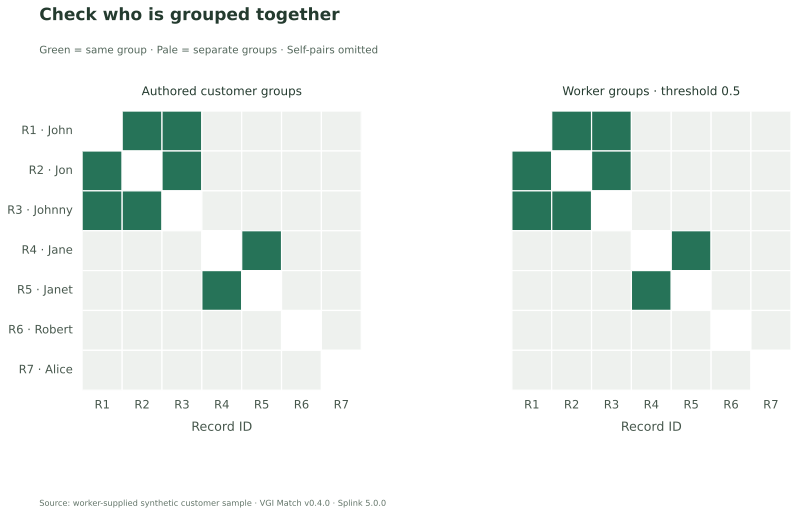

The matrix is symmetric, so each unordered pair appears twice visually. The audit and metrics count it once. Green cells express a partition, not the strength of a direct pair link.

In [12]:
ids = audit.record_id.tolist()
labels = [f"{r.record_id} · {r.first_name}" for r in audit.itertuples()]
position = {key: index for index, key in enumerate(ids)}
fig, axes = plt.subplots(1, 2, figsize=(12, 7.6), sharex=True, sharey=True)
for ax, field, title in zip(
    axes,
    ["expected_together", "predicted_together"],
    ["Authored customer groups", f"Worker groups · threshold {THRESHOLD:g}"],
    strict=True,
):
    matrix = np.zeros((len(ids), len(ids)))
    for row in pairs.itertuples():
        i, j = position[row.left_id], position[row.right_id]
        matrix[i, j] = matrix[j, i] = getattr(row, field)
    sns.heatmap(
        matrix,
        mask=np.eye(len(ids), dtype=bool),
        ax=ax,
        cmap=ListedColormap(["#eef1ee", "#267358"]),
        vmin=0,
        vmax=1,
        cbar=False,
        square=True,
        linewidths=1.2,
        linecolor="white",
        xticklabels=ids,
        yticklabels=labels,
    )
    ax.set_title(title, fontsize=12, pad=16)
    ax.tick_params(axis="both", rotation=0)
    ax.set_xlabel("Record ID")
    ax.set_ylabel("")
axes[1].tick_params(axis="y", labelleft=False)
finish(
    fig,
    "Check who is grouped together",
    "Green = same group · Pale = separate groups · Self-pairs omitted",
    SOURCE,
    name=f"pair-membership-threshold-{THRESHOLD:g}",
)
prose(
    "The matrix is symmetric, so each unordered pair appears twice visually. "
    "The audit and metrics count it once. Green cells express a partition, not the strength of a direct pair link."
)

### Count recovered and missed labeled pairs

Pair precision divides correctly grouped pairs by all pairs grouped together.
Pair recall divides correctly grouped pairs by all authored positive pairs. If no
pairs are grouped, precision is **undefined (SQL NULL)**, not 100% or zero.
Separating every row avoids false groupings on this fixture but misses duplicate pairs.

In [13]:
%%sql
CREATE TABLE pair_counts AS
SELECT count(*) AS all_pairs,
 count(*) FILTER (WHERE expected_together AND predicted_together) AS recovered,
 count(*) FILTER (WHERE expected_together AND NOT predicted_together) AS missed,
 count(*) FILTER (WHERE NOT expected_together AND predicted_together) AS falsely_grouped,
 count(*) FILTER (WHERE NOT expected_together AND NOT predicted_together) AS correctly_separate,
 count(*) FILTER (WHERE candidate_by_default_blocking) AS candidate_pairs,
 count(*) FILTER (WHERE expected_together AND NOT candidate_by_default_blocking) AS positives_missed_by_blocking
FROM pair_audit;
CREATE TABLE pair_metrics AS
SELECT *,recovered::DOUBLE/nullif(recovered+falsely_grouped,0) AS pair_precision,
 recovered::DOUBLE/nullif(recovered+missed,0) AS pair_recall
FROM pair_counts;
SELECT * FROM pair_metrics;

,all_pairs,recovered,missed,falsely_grouped,correctly_separate,candidate_pairs,positives_missed_by_blocking,pair_precision,pair_recall
0,21,4,0,0,17,5,0,1.0,1.0


In [14]:
%%sql metrics <<
SELECT * FROM pair_metrics;

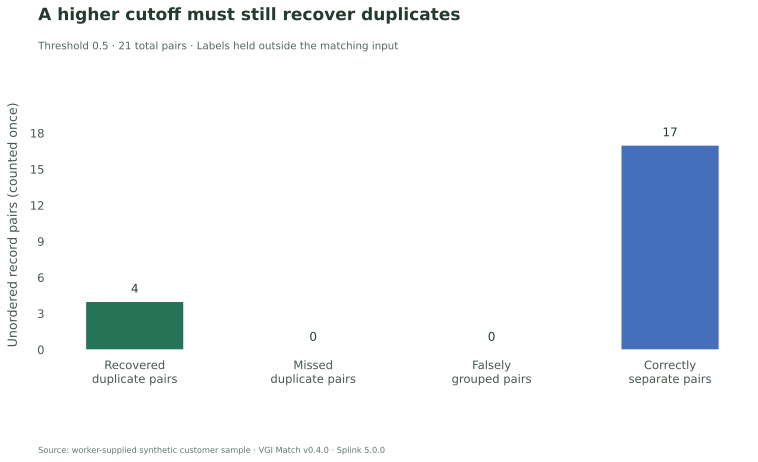

The result recovers **4 of 4 authored duplicate pairs**, misses **0**, and falsely groups **0**. Pair precision is **100%**; recall is **100%**. The default blocking rule considers **5 of 21 pairs**, missing **0 authored positives** before scoring. These values describe only the synthetic fixture; they are not estimates of performance on new records.

In [15]:
m = metrics.iloc[0]
values = [int(m.recovered), int(m.missed), int(m.falsely_grouped), int(m.correctly_separate)]
labels = [
    "Recovered\nduplicate pairs",
    "Missed\nduplicate pairs",
    "Falsely\ngrouped pairs",
    "Correctly\nseparate pairs",
]
fig, ax = plt.subplots(figsize=(11, 6.8))
bars = ax.bar(labels, values, color=["#267358", "#c57b40", "#a84e4e", "#456fba"], width=0.55)
ax.bar_label(bars, padding=6, fontsize=12)
ax.set_ylim(0, max(values + [1]) * 1.22)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("Unordered record pairs (counted once)")
ax.grid(axis="x", visible=False)
finish(
    fig,
    "A higher cutoff must still recover duplicates",
    f"Threshold {THRESHOLD:g} · {int(m.all_pairs)} total pairs · Labels held outside the matching input",
    SOURCE,
    name=f"pair-outcomes-threshold-{THRESHOLD:g}",
)
precision = (
    "undefined (no predicted positive pairs)"
    if pd.isna(m.pair_precision)
    else f"{m.pair_precision:.0%}"
)
recall = (
    "undefined (no authored positive pairs)" if pd.isna(m.pair_recall) else f"{m.pair_recall:.0%}"
)
prose(
    f"The result recovers **{int(m.recovered)} of {int(m.recovered + m.missed)} authored duplicate pairs**, "
    f"misses **{int(m.missed)}**, and falsely groups **{int(m.falsely_grouped)}**. "
    f"Pair precision is **{precision}**; recall is **{recall}**. "
    f"The default blocking rule considers **{int(m.candidate_pairs)} of {int(m.all_pairs)} pairs**, "
    f"missing **{int(m.positives_missed_by_blocking)} authored positives** before scoring. "
    "These values describe only the synthetic fixture; they are not estimates of performance on new records."
)

### Verify that the evaluation kept every row and pair

These checks establish row preservation, valid scores, complete pair coverage and
consistent metric denominators. They intentionally do not require perfect matching:
the threshold experiment should be allowed to expose missed duplicates.

In [16]:
%%sql checks <<
SELECT 'Every input row returned once' AS check_name,
 (SELECT count(*) FROM resolved)=(SELECT count(*) FROM customers)
 AND (SELECT count(DISTINCT record_id) FROM resolved)=(SELECT count(*) FROM customers) AS passed
UNION ALL SELECT 'Passthrough values unchanged',NOT EXISTS (
 SELECT record_id,first_name,last_name,email,city FROM resolved
 EXCEPT SELECT * FROM customers)
UNION ALL SELECT 'Every row has one authored label',
 (SELECT count(*) FROM cluster_audit)=(SELECT count(*) FROM customers)
UNION ALL SELECT 'Scores and cluster IDs present and bounded',
 NOT EXISTS(SELECT 1 FROM resolved WHERE cluster_id IS NULL OR match_probability IS NULL OR match_probability NOT BETWEEN 0 AND 1)
UNION ALL SELECT 'Singleton convention preserved',
 NOT EXISTS(SELECT 1 FROM cluster_audit WHERE cluster_size=1 AND match_probability<>1)
UNION ALL SELECT 'Every unordered pair appears once',
 (SELECT count(*) FROM pair_audit)=(SELECT count(*)*(count(*)-1)/2 FROM customers)
 AND (SELECT count(DISTINCT (left_id,right_id)) FROM pair_audit)=(SELECT count(*) FROM pair_audit)
UNION ALL SELECT 'Outcome counts partition the pairs',
 recovered+missed+falsely_grouped+correctly_separate=all_pairs FROM pair_metrics
UNION ALL SELECT 'Candidate coverage bounded',
 candidate_pairs<=all_pairs AND positives_missed_by_blocking<=recovered+missed FROM pair_metrics
UNION ALL SELECT 'Precision denominator or NULL is correct',
 CASE WHEN recovered+falsely_grouped=0 THEN pair_precision IS NULL
 ELSE pair_precision=recovered::DOUBLE/(recovered+falsely_grouped) END FROM pair_metrics
UNION ALL SELECT 'Recall denominator or NULL is correct',
 CASE WHEN recovered+missed=0 THEN pair_recall IS NULL
 ELSE pair_recall=recovered::DOUBLE/(recovered+missed) END FROM pair_metrics;

In [17]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} consistency checks passed.** The rows, labels, pair universe and score conventions remain accounted for."
)

**10 consistency checks passed.** The rows, labels, pair universe and score conventions remain accounted for.

### Experiment · require a much stronger pair link

Change only `THRESHOLD` from `0.5` to `0.9999`, restart, and run all. Predict what
happens to the green matrix cells, cluster count, singleton scores and pair recall.
Compare the two charts and the explicit precision denominator. The labeled customer
population must stay fixed.

A high cutoff can split known duplicate groups while producing more raw row scores
of 1.0. That apparent increase is the singleton convention, not stronger evidence.
This experiment measures sensitivity to one cutoff in a fixed untrained model; it
does not select a production threshold. A representative labeled evaluation set and
an explicit cost for false merges versus missed matches would be needed for that.

Reset `THRESHOLD=0.5` to recover the saved default example.

In [18]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-match](https://github.com/Query-farm/vgi-match)
